# **Kaya mo naman pala e, bakit pag dating sa ‘kin hirap na hirap ka?: Why Your Model Trains Fine in Class but Falls Apart on Your Own Learning Rate**

### Comparing four learning rates (0.0001, 0.001, 0.01, 0.1) on a small CNN trained on Fashion-MNIST

 Yvonne D. Bitco &nbsp;|&nbsp; **Course:** Deep Learning &nbsp;|&nbsp; **Date:** November 2026
**Code:** this notebook (GitHub repository: [PASTE YOUR REPO LINK HERE])

## **How to rerun this experiment**
1. Open the notebook in Google Colab. This experiment runs on CPU; a GPU is not required.
2. Run the cells from top to bottom. If you restart the runtime, start again from the installation cell.
3. The notebook saves three files next to it: `fig1_loss_curves.png`, `fig2_accuracy_curves.png`, and `lr_summary_table.csv`.
All randomness is controlled by one seed (42), so a rerun on the same hardware should give the same numbers. Results may differ slightly across hardware.

## 1. The question (hook)

Ever tried doing the same thing that everyone else does but come up with something different? Well, that is what I experienced in my experiment of Deep Learning. In class, your notebook worked well, but when using different learning rates with myself, it started to perform differently.

This got me thinking about the effect of a learning rate on the ability of a model to learn. A single change of anything, such as a single hyperparameter, can mean a change of results even with the same data, architecture and optimizer.

Research questions: What is the optimal learning rate (0.0001, 0.001, 0.01, or 0.1) for a small CNN trained on Fashion MNIST for 10 epochs, and what are the main differences in the training and validation curve for each of these learning rates?

## 2. Explanation: what is a learning rate?

A learning rate is a hyperparameter that controls how much a model adjusts its weights during training. An epoch refers to one complete pass through the training dataset, while loss measures how far the model's predictions are from the correct answers. The validation set is used to evaluate how well the model performs on data it has not trained on.

When the learning rate is too small, the model learns slowly because its weight adjustments are smaller. When it is too large, the model may make excessive updates and struggle to reach better results.
>
> The standard gradient descent update rule is:
> $$\theta \leftarrow \theta - \eta \, \nabla_\theta \mathcal{L}(\theta)$$
>
> where $\theta$ are the weights, $\eta$ is the learning rate and $\mathcal{L}$ is the loss.

In this experiment, Adam was used, which automatically adjusts the step sizes for individual parameters based on previous gradients. However, choosing an appropriate learning rate is still important because excessively large updates can affect training stability and performance.

The learning rate matters because it affects how quickly and effectively a model learns. This experiment uses the Adam optimizer, which adapts the step size for individual weights based on previous gradients. However, choosing an appropriate learning rate is still important because Adam cannot completely prevent problems caused by an excessively high learning rate.

## 3. Experiment setup

Everything below is **fixed** across all four runs. Only the learning rate changes.

| Item | Value |
|---|---|
| Dataset | Fashion-MNIST (28×28 grayscale clothing images, 10 classes) |
| Training data | 10,000 images (a random subset, to keep runs short) |
| Validation data | 6,000 images (held out from the original 60,000 training images) |
| Test set | Not used |
| Model | Small CNN: 2 conv blocks (32 and 64 channels, BatchNorm, ReLU, MaxPool), dropout 0.25, hidden layer of 128 units |
| Trainable parameters | [FILL IN from the model cell output] |
| Optimizer | Adam (no weight decay, no scheduler, no early stopping) |
| **Learning rates compared** | **0.0001, 0.001, 0.01, 0.1** |
| Batch size | 64 |
| Epochs | 10 |
| Seed | 42 (same data split, same initial weights, same shuffling for every run) |
| Hardware | [FILL IN: e.g. Colab T4 GPU or CPU] |

Model and data pipeline adapted from the class notebook `hyperparameters_lightning.ipynb`.
All comparisons use the **validation set** only.

In [18]:
%pip install -q lightning

import torch
import lightning as L

print("PyTorch version:", torch.__version__)
print("Lightning version:", L.__version__)
print("GPU Available:", torch.cuda.is_available())
print("Environment is fully ready!")

PyTorch version: 2.14.1+cpu
Lightning version: 2.6.6
GPU Available: False
Environment is fully ready!


In [19]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

try:
    import lightning as L
    from lightning.pytorch.loggers import CSVLogger
except ImportError:
    import pytorch_lightning as L
    from pytorch_lightning.loggers import CSVLogger

warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*logging interval.*")

# Fixed setup: only the learning rate changes between runs.
SEED = 42
EPOCHS = 10
BATCH_SIZE = 64
TRAIN_SUBSET = 10_000      # training images used per run
VAL_FRACTION = 0.1         # 6,000 of the 60,000 images held out for validation
LEARNING_RATES = [1e-4, 1e-3, 1e-2, 1e-1]

print("torch:", torch.__version__, "| GPU:", torch.cuda.is_available())

torch: 2.14.1+cpu | GPU: False


In [20]:
tfm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),   # Fashion-MNIST mean and std
])
full = datasets.FashionMNIST("./data", train=True, download=True, transform=tfm)

# Same split every run (fixed seed). The test set is never touched.
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(full), generator=g).tolist()
n_val = int(len(full) * VAL_FRACTION)
val_idx, train_idx = idx[:n_val], idx[n_val:][:TRAIN_SUBSET]

train_ds = Subset(full, train_idx)
val_ds = Subset(full, val_idx)
print(f"train: {len(train_ds):,}   validation: {len(val_ds):,}")

train: 10,000   validation: 6,000


In [21]:
class LitCNN(L.LightningModule):
    def __init__(self, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Dropout(0.25), nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(0.25), nn.Linear(128, 10),
        )
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, x):
        return self.net(x)

    def _step(self, batch, stage):
        x, y = batch
        logits = self(x)
        loss = self.loss_fn(logits, y)
        acc = (logits.argmax(dim=1) == y).float().mean()
        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True)
        self.log(f"{stage}_acc", acc, on_step=False, on_epoch=True)
        return loss

    def training_step(self, batch, batch_idx):
        return self._step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._step(batch, "val")

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)


n_params = sum(p.numel() for p in LitCNN(1e-3).parameters() if p.requires_grad)
print(f"trainable parameters: {n_params:,}")

trainable parameters: 421,834


In [22]:
def train_one(lr):
    L.seed_everything(SEED, workers=True)       # same seed for every run
    model = LitCNN(lr)                          # fresh weights for every run
    logger = CSVLogger("logs", name=f"lr_{lr:g}")
    trainer = L.Trainer(
        max_epochs=EPOCHS,
        accelerator="auto",
        devices=1,
        logger=logger,
        enable_checkpointing=False,
        enable_progress_bar=False,
        enable_model_summary=False,
        log_every_n_steps=10,
        deterministic=True
    )
    trainer.fit(
        model,
        DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True),
        DataLoader(val_ds, batch_size=512),
    )
    df = pd.read_csv(Path(logger.log_dir) / "metrics.csv")
    cols = ["train_loss", "val_loss", "train_acc", "val_acc"]
    # Average the logged metrics within each epoch (one row per epoch)
    df_epoch = df.groupby("epoch")[cols].mean().reset_index()
    return df_epoch

## What theory led me to expect

The model's training should be different for each learning rate.
*  **Learning rate = 0.0001**: low learning rate: This learning rate was going to be low and that the model would learn slowly. The training and validation losses of this model would likely decline over time, but it may require additional epochs to achieve higher accuracy. if it had enough time to train it could perform well.
*   **Learning rate = 0.001**: This would yield the greatest success as it is a balance between learning rate and stability. The accuracy should steadily rise during training and validation and the losses should steadily decrease.
*   **Learning rate = 0.01**: The model should learn quicker when using learning rate of 0.01 than with the previous two rates. Some variations in its validation performance may be present though as larger updates become more difficult to converge the model to better weights.
*   **Learning rate = 0.1**: The learning rate would do worst, as it could be too big for the model. The training and validation losses should be higher and more unstable, making it difficult to achieve good accuracy.





In [23]:
results = {}
for lr in LEARNING_RATES:
    start = time.perf_counter()
    results[f"lr={lr:g}"] = train_one(lr)
    best = results[f"lr={lr:g}"]["val_acc"].max()
    print(f"lr={lr:g}: best val_acc = {best:.4f}  ({time.perf_counter() - start:.0f}s)")

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and

lr=0.0001: best val_acc = 0.8830  (240s)


INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13

lr=0.001: best val_acc = 0.8977  (236s)


INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.
INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13

lr=0.01: best val_acc = 0.8805  (234s)


INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


lr=0.1: best val_acc = 0.6970  (228s)


# 4. Results
The  trained them for 10 epochs, using four learning rates, and compared their respective training loss, validation loss, training accuracy and validation accuracy.

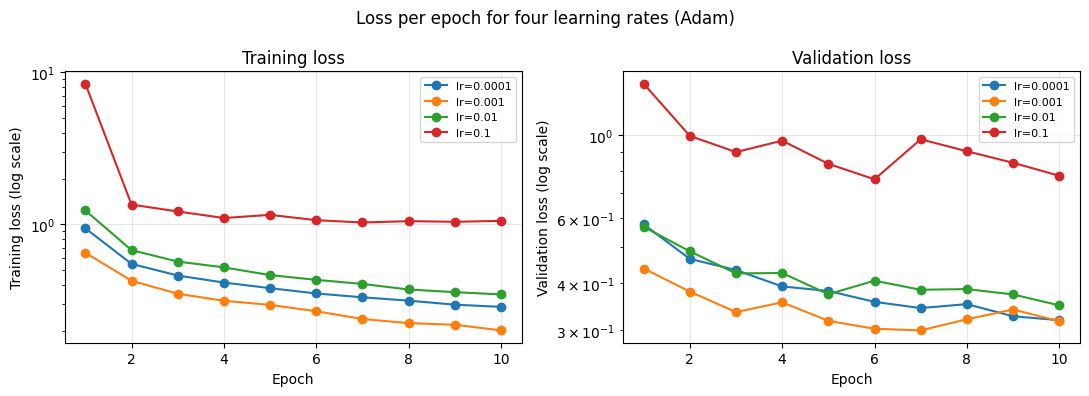

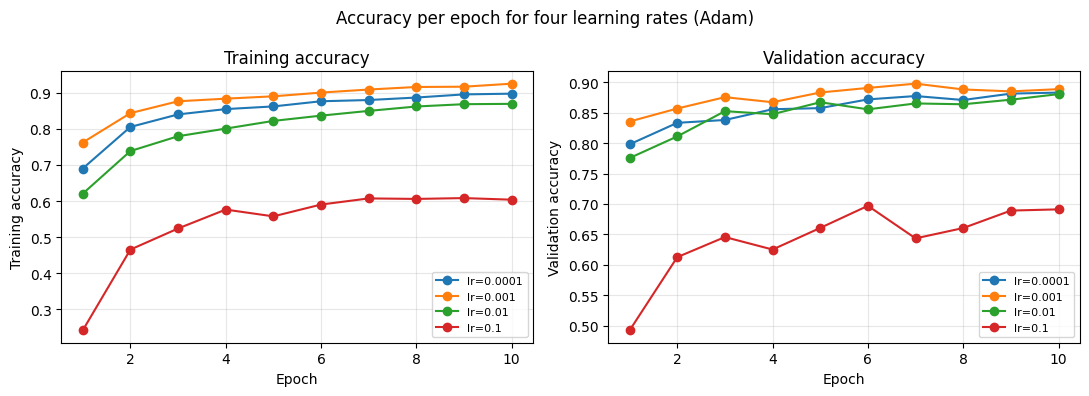

,final_train_loss,final_val_loss,final_val_acc,best_val_acc,best_epoch
lr=0.0001,0.2882,0.3188,0.8830,0.8830,10
lr=0.001,0.2020,0.3168,0.8887,0.8977,7
lr=0.01,0.3478,0.3494,0.8805,0.8805,10
lr=0.1,1.0564,0.7786,0.6912,0.6970,6


In [24]:
def save_curves(results, metrics, titles, fname, suptitle):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.5 * len(metrics), 4))
    for ax, metric, title in zip(axes, metrics, titles):
        for label, h in results.items():
            ax.plot(h["epoch"] + 1, h[metric], "o-", label=label)
        ax.set(xlabel="Epoch", ylabel=title, title=title)
        ax.grid(alpha=0.3)
        if "loss" in metric:
            ax.set_yscale("log")   # lr=0.1 starts near 8, so a log scale keeps the other curves readable
            ax.set_ylabel(title + " (log scale)")
        ax.legend(fontsize=8)
    fig.suptitle(suptitle)
    plt.tight_layout()
    fig.savefig(fname, dpi=150)
    plt.show()


save_curves(results, ("train_loss", "val_loss"), ("Training loss", "Validation loss"),
            "fig1_loss_curves.png", "Loss per epoch for four learning rates (Adam)")

save_curves(results, ("train_acc", "val_acc"), ("Training accuracy", "Validation accuracy"),
            "fig2_accuracy_curves.png", "Accuracy per epoch for four learning rates (Adam)")

table = pd.DataFrame({
    label: {
        "final_train_loss": h["train_loss"].iloc[-1],
        "final_val_loss": h["val_loss"].iloc[-1],
        "final_val_acc": h["val_acc"].iloc[-1],
        "best_val_acc": h["val_acc"].max(),
        "best_epoch": int(h["val_acc"].idxmax()) + 1,
    }
    for label, h in results.items()
}).T.round(4)
table["best_epoch"] = table["best_epoch"].astype(int)
table.to_csv("lr_summary_table.csv")
table

> **Figure 1.** The graphs show that learning rates of 0.0001, 0.001, and 0.01 gradually decreased their training losses, while 0.1 maintained considerably higher losses. The validation losses of the first three learning rates remained relatively low compared with 0.1.
>
> **Figure 2.** The graphs show that the learning rate of 0.001 achieved the highest validation accuracy of 89.77% at epoch 7, while 0.1 performed the worst with a maximum validation accuracy of 69.70%.
>
> **Table 1.** The table shows that the learning rate of 0.001 achieved the highest validation accuracy of 89.77%, followed by 0.0001 at 88.30%, 0.01 at 88.05%, and 0.1 at 69.70%.

In [25]:
# Optional: download the output files (Colab only).
try:
    from google.colab import files
    for f in ["fig1_loss_curves.png", "fig2_accuracy_curves.png", "lr_summary_table.csv"]:
        files.download(f)
except ImportError:
    print("Not running on Colab: the files are saved next to the notebook.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Discussion

1.   Which learning rate had the best validation performance? Which was worst,
and what did its curve look like (slow, noisy, stuck, diverging)?
      - The learning rate with 0.001 achieved the best accuracy during validation of 89.77% at epoch 7. Training loss progressively decreased, and the validation loss stayed relatively low throughout the experiment. But 0.1 had lowest validation accuracy of 69.70%. It was lost at a significant level and was not as stable as the other learning rates; its accuracy was much less than the other learning rates. This indicates that the learning rate was too high to be able to learn the model correctly.
2.    Is the lowest learning rate still improving at epoch 10? Would more epochs change the ranking?
      - Yes. The learning rate of 0.0001 was still improving at epoch 10, as its training loss continued to decrease and its training and validation accuracy gradually increased. This suggests that the model may benefit from additional training. However, it is uncertain whether more epochs would change the ranking because the learning rate of 0.001 already achieved better validation performance.

3.   Does the gap between training and validation loss differ between learning rates?
     - Yes. The difference varies across learning rates. The learning rate of 0.01 had very similar final training and validation losses of 0.3478 and 0.3494, respectively. Meanwhile, 0.001 had a training loss of 0.2020 and validation loss of 0.3168. These differences show that learning rates affect how the model performs on training and validation data.
  
4. Did the results match your predictions? If not, why do you think they differed?
   - The results mostly matched my predictions. The learning rate of 0.001 achieved the highest validation accuracy of 89.77%, while 0.1 performed the worst at 69.70%. However, 0.01 also performed well with 88.05% accuracy, despite my expectation of more fluctuations. This may be due to Adam and batch normalization, which help stabilize training. Still, a learning rate that is too high can cause large updates and reduce model performance.

5.  **Limitations** (name at least one):
    - There are some restrictions to this experiment. Firstly, the entire Fashion-MNIST training set was not used but only 10,000 training images. Second, the model was only trained for 10 epochs creating the possibility of not capturing the model's learning capability. The experiment was also conducted with just one random seed, one model architecture, just one optimizer (Adam). Moreover, the test set was not used, therefore results only represent validation performance and does not reflect the model's performance on totally new test data.












## 6. Takeaways
> 1. **Choosing the right learning rate matters.** A learning rate that is too high can make training unstable, while a very low learning rate may require more time to reach better performance.
> 2. **Higher training accuracy does not always mean better performance.** Validation results are important because they help determine how well the model performs on data it has not trained on.
> 3. **Experimentation is important in deep learning.** Even when using the same model and optimizer, changing one hyperparameter can significantly affect the results. In this experiment, 0.001 provided the best validation performance.

## References

*Keep only the sources you actually used, and add any tutorial or page you took ideas or code from.*

- Class notebook: `hyperparameters.ipynb` (PyTorch Lightning, Fashion-MNIST). Model and data pipeline adapted from it.
- PyTorch Lightning documentation: https://lightning.ai/docs/pytorch/stable/
- Xiao, H., Rasul, K., Vollgraf, R. (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms.* https://arxiv.org/abs/1708.07747
- Kingma, D. P., Ba, J. (2014). *Adam: A Method for Stochastic Optimization.* https://arxiv.org/abs/1412.6980

## Note on AI tool use

 I wrote my own first drafts of the explanation, predictions, figure and table captions, discussion and takeaways, based on my own results. I used ChatGPT to correct the grammar of those drafts and rephrase my sentences so they read more clearly, and I copied the corrected versions into this post. I used Claude (Anthropic) to help draft the starter code for the training loop and plotting, to help debug the notebook, and to check grammar and the clarity of some sections. The experiment, the figures and my interpretation of the results are my own.